# 03 在线探索与预算节奏

三段变化的模拟环境，每轮一个用户，动作是 0/1/2 单位补贴。奖励为次日活跃价值减成本。比较固定、贪心、窗口 UCB；这些简化策略仅供教学。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.style.use('seaborn-v0_8-whitegrid')
rng=np.random.default_rng(2026);T=6000
amounts=np.array([0,1,2]);cost=.07*amounts
segments=np.repeat(np.arange(3),T//3)
prob=np.array([[.35,.48,.52],[.42,.51,.55],[.38,.44,.47]])[segments]
value=prob-cost;oracle=value.max(axis=1)
display(pd.DataFrame(np.array([[.35,.48,.52],[.42,.51,.55],[.38,.44,.47]])-cost,columns=amounts))

,0,1,2
0,0.35,0.41,0.38
1,0.42,0.44,0.41
2,0.38,0.37,0.33


## 决策和预算护栏

窗口估计适应变化；UCB 给少观察的动作探索机会。每 200 轮设置预算块，选择前过滤不可支付动作。真实系统还需预测流量和长期反馈。

In [2]:
def run(kind,seed,budget=.9,block=200,window=350):
    rr=np.random.default_rng(seed);actions=[];net=[];active=[];spent=[]
    for t in range(T):
        if t%block==0:remaining=budget*block
        start=max(0,t-window)
        aa=np.array(actions[start:]);nn=np.array(net[start:])
        counts=np.array([(aa==a).sum() for a in range(3)])
        means=np.array([nn[aa==a].mean() if counts[a] else 0 for a in range(3)])
        if kind=='fixed':order=np.array([1,0,2])
        elif kind=='greedy':order=np.argsort(-means)
        else:
            score=means+np.sqrt(2*np.log(min(t,window)+2)/np.maximum(counts,1))
            score[counts==0]=np.inf
            order=np.argsort(-score)
        affordable=[a for a in order if amounts[a]<=remaining+1e-9]
        a=int(affordable[0]) if affordable else 0
        outcome=int(rr.random()<prob[t,a])
        actions.append(a);active.append(outcome);net.append(outcome-cost[a]);spent.append(amounts[a])
        remaining-=amounts[a]
    return pd.DataFrame({'action':actions,'active':active,'net':net,'spend':spent,
                         'expected_net':value[np.arange(T),actions],'oracle':oracle})
runs={k:run(k,2026+i) for i,k in enumerate(['fixed','greedy','ucb'])}
summary=pd.DataFrame({k:{'mean net':d.net.mean(),'mean expected net':d.expected_net.mean(),
                         'mean spend':d.spend.mean(),'total regret':(d.oracle-d.expected_net).sum()}
                      for k,d in runs.items()}).T
display(summary)

,mean net,mean expected net,mean spend,total regret
fixed,0.393333,0.404333,0.900000,34.00
greedy,0.376500,0.383333,0.000000,160.00
ucb,0.395012,0.389068,0.883167,125.59


## 学习曲线

后悔值使用模拟器已知的潜在概率计算，现实业务中无法直接观察。虚线表示环境变化时点。

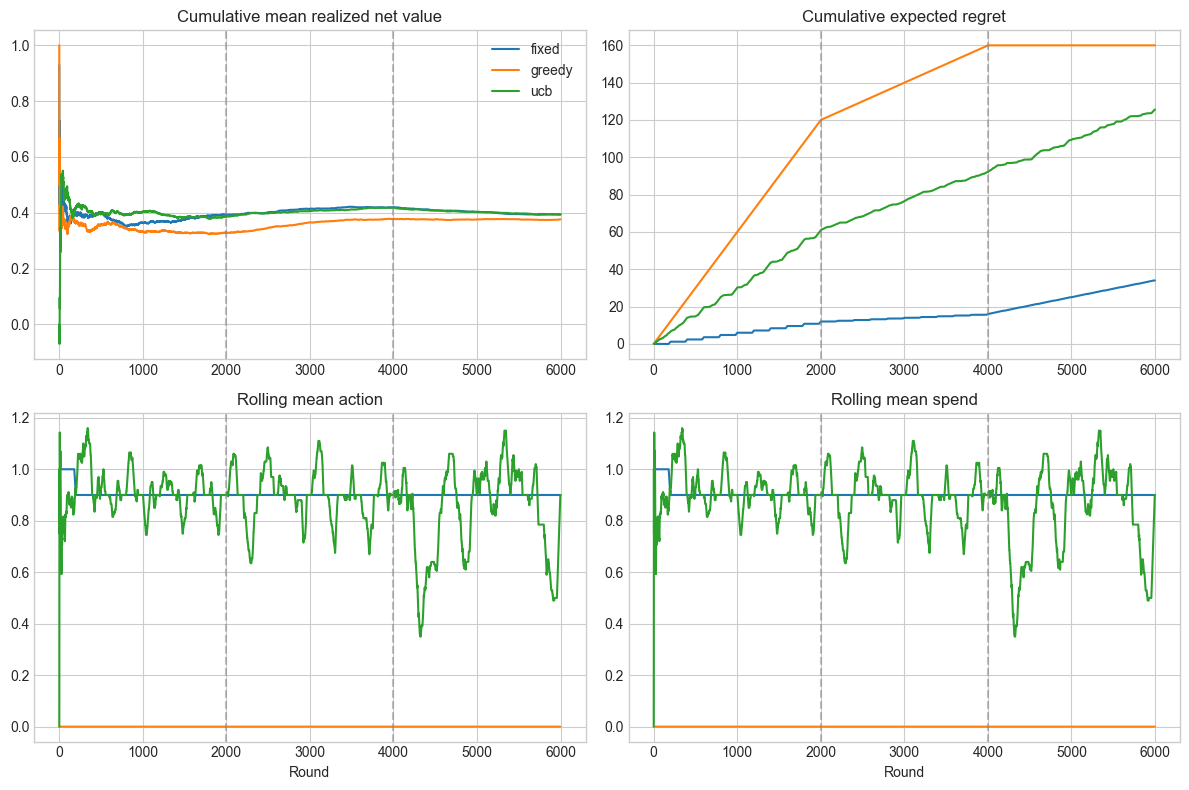

In [3]:
fig,ax=plt.subplots(2,2,figsize=(12,8))
for name,d in runs.items():
    ax[0,0].plot(d.net.expanding().mean(),label=name)
    ax[0,1].plot((d.oracle-d.expected_net).cumsum(),label=name)
    ax[1,0].plot(d.action.rolling(200,min_periods=1).mean(),label=name)
    ax[1,1].plot(d.spend.rolling(200,min_periods=1).mean(),label=name)
for a in ax.ravel():
    for boundary in [2000,4000]:a.axvline(boundary,color='gray',linestyle='--',alpha=.5)
ax[0,0].set(title='Cumulative mean realized net value')
ax[0,1].set(title='Cumulative expected regret')
ax[1,0].set(title='Rolling mean action',xlabel='Round')
ax[1,1].set(title='Rolling mean spend',xlabel='Round')
ax[0,0].legend();plt.tight_layout();plt.show()

## 预算敏感性

比较价值与花费，并验证任何 200 轮预算块都没有超支。注意块末可能被迫集中使用零补贴，实际需要更平滑的 pacing。

,budget,strategy,expected_net,mean_spend,max_block_spend
0,0.4,fixed,0.392667,0.400000,80
1,0.4,greedy,0.383333,0.000000,0
2,0.4,ucb,0.385707,0.400000,80
3,0.7,fixed,0.399667,0.700000,140
4,0.7,greedy,0.383333,0.000000,0
5,0.7,ucb,0.388078,0.700000,140
6,1.0,fixed,0.406667,1.000000,200
7,1.0,greedy,0.383333,0.000000,0
8,1.0,ucb,0.389308,0.963833,200
9,1.4,fixed,0.406667,1.000000,200


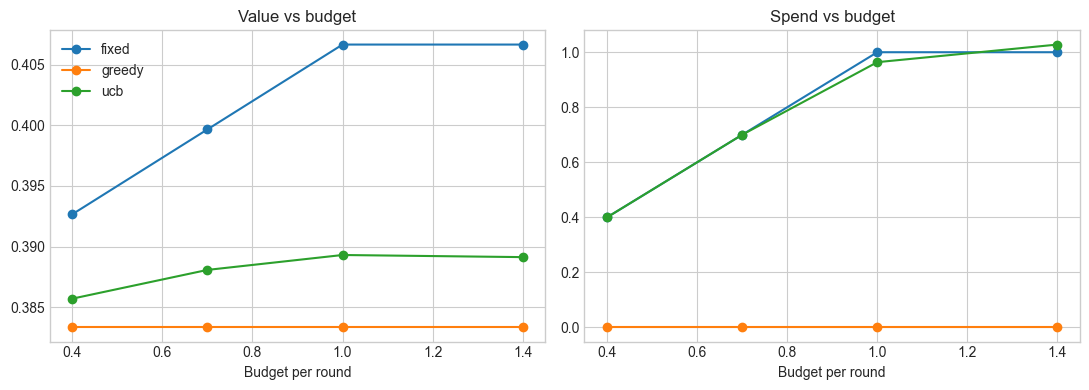

In [4]:
rows=[]
for budget in [.4,.7,1.,1.4]:
    for i,name in enumerate(['fixed','greedy','ucb']):
        d=run(name,100+int(budget*10)+i,budget=budget)
        rows.append((budget,name,d.expected_net.mean(),d.spend.mean(),d.groupby(np.arange(T)//200).spend.sum().max()))
s=pd.DataFrame(rows,columns=['budget','strategy','expected_net','mean_spend','max_block_spend'])
display(s)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for name,g in s.groupby('strategy'):
    ax[0].plot(g.budget,g.expected_net,marker='o',label=name)
    ax[1].plot(g.budget,g.mean_spend,marker='o',label=name)
ax[0].set(title='Value vs budget',xlabel='Budget per round')
ax[1].set(title='Spend vs budget',xlabel='Budget per round')
ax[0].legend();plt.tight_layout();plt.show()
assert (s.max_block_spend<=s.budget*200+1e-8).all()

## 结论与真实数据接口

在线探索能适应变化，但会产生探索成本。这里没有用户特征、延迟反馈、干扰、欺诈或体验约束。上线应从安全基线和小流量实验开始，逐步加入上下文特征、频控、预算 pacing 和回退策略。真实日志需保存候选集、动作概率、预算状态、反馈时间及长期留存。